In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn  as sns

In [2]:
df= pd.read_csv('retail_sales_dataset.csv')
df.head()


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


In [167]:
df.duplicated().sum()

np.int64(0)

In [71]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [72]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

In [73]:
df.shape

(1000, 9)

In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


Load the dataset and calculate mean,median and mode

In [75]:

numeric_data=df.select_dtypes(include="number")
print("Mean:")
print(numeric_data.mean())
print("\nMedian:")
print(numeric_data.median())
print("\nMode:")
print(numeric_data.mode())

Mean:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
     Transaction ID   Age  Quantity  Price per Unit  Total Amount
0                 1  43.0       4.0            50.0          50.0
1                 2  64.0       NaN             NaN           NaN
2                 3   NaN       NaN             NaN           NaN
3                 4   NaN       NaN             NaN           NaN
4                 5   NaN       NaN             NaN           NaN
..              ...   ...       ...             ...           ...
995             996   NaN       NaN             NaN           NaN
996             997   NaN       NaN             NaN           NaN
997             998   NaN       NaN             NaN           NaN
998             999   NaN       NaN   

In [ ]:
df["Date"]=pd.to_datetime(df["Date"])
df["Month"]= df["Date"].dt.to_period("M")
df["Quarter"]= df["Date"].dt.to_period("Q")




In [ ]:
monthly_sales= df.groupby("Month")["Total Amount"].sum()
print(monthly_sales)


Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


In [90]:
quarterly_sales=df.groupby("Quarter")["Total Amount"].sum()
print(quarterly_sales)

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


Plot monthly sales

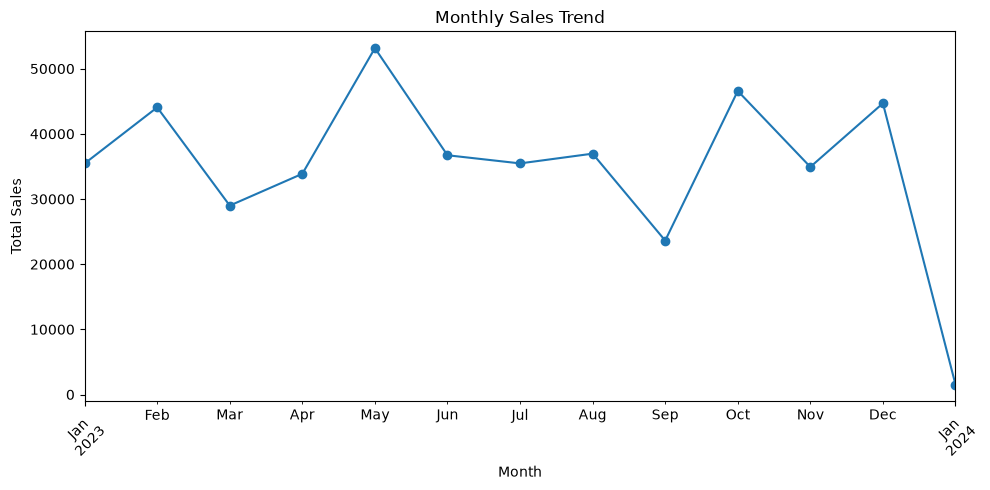

In [91]:
monthly_sales.plot(kind="line",marker="o",figsize=(10,5))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly sales show considerable fluctuation throughout the year ,with May recording the highest sales and September experiencing  a significant decline. 

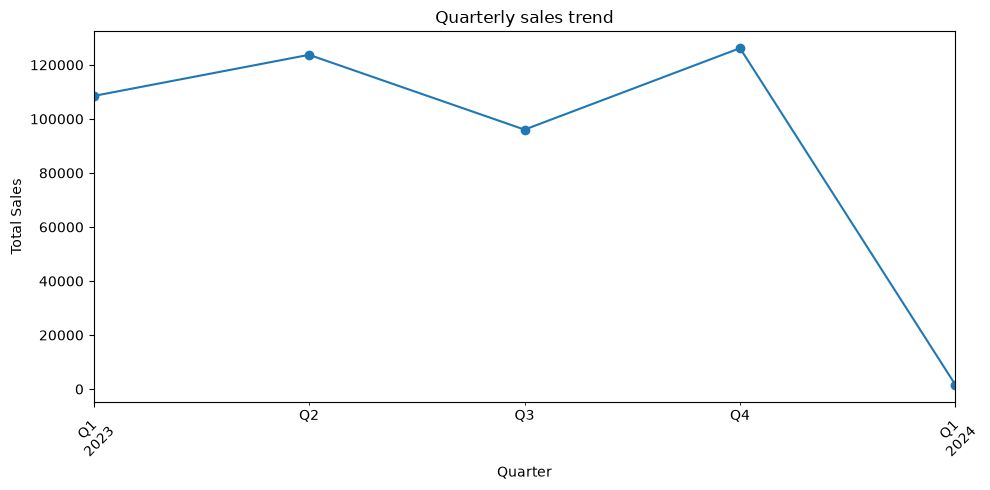

In [92]:
quarterly_sales.plot(kind="line",marker="o",figsize=(10,5))
plt.title("Quarterly sales trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q4 recorded the highest quarterly sales,while Q3 had the lowest sales among the four quarters. the results suggests that sales performance varied throughout the year ,with a strong improvement toward the end of 2023.

Customer Age Group Analysis

Customer  age Group Distribution: 
Age Group
Under 18     21
18-30       252
31-45       303
46-60       331
60+          93
Name: count, dtype: int64


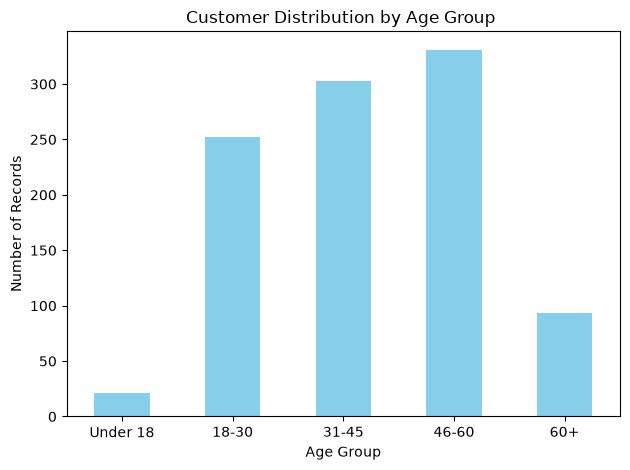

In [93]:
#Create age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0,18,30,45,60,100],
    labels=["Under 18","18-30","31-45","46-60","60+"]

)
#Count customer in each group
age_count=df["Age Group"].value_counts().sort_index()
print("Customer  age Group Distribution: ")
print(age_count)

#plot age group distribution
age_count.plot(kind="bar",color="skyblue")
plt.title("Customer Distribution by Age Group ")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Most customer belongs to the 31-60 age  range, particularly the 46-60 group.


In [94]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Quarter', 'Age Group']


In [106]:
if "Product" in df.columns:
    top_products = (df.groupby("Product")["Total Amount"]).sum().sort_values(ascending=False).head(10)
    print("Top 10 Best-selling Products: ")
    print(top_products)

    top_products.sort_values().plot(kind='bar',color = "skyblue")
    plt.title("Top 10 Best Selling Products")
    plt.xlabel("Total Sales Reveneue")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()
else:
    print("Individual product-name column not found.")
    print("Top 10 product categories will be analyzed instead.")

    top_categories=(df.groupby("Product Category")["Total Amount"]).sum().sort_values(ascending=False).head(10)
    print(top_categories)

Individual product-name column not found.
Top 10 product categories will be analyzed instead.
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [111]:
top_categories=(df.groupby("Product Category")["Total Amount"]).sum().sort_values(ascending=False).head(10)
print(top_categories)



Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


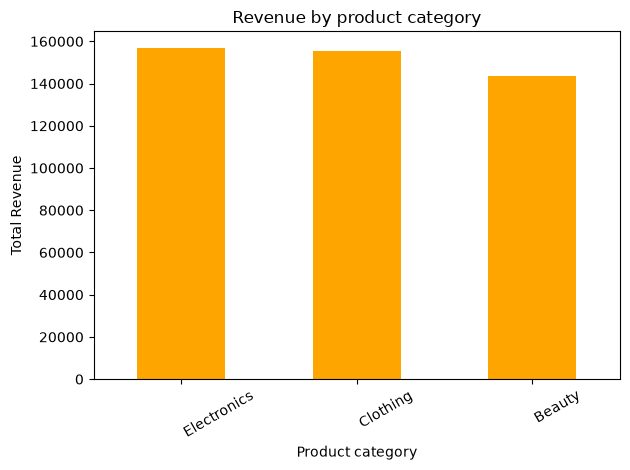

In [126]:
category_revenue=(df.groupby("Product Category")["Total Amount"]).sum().sort_values(ascending=False)
print(category_revenue)
category_revenue.plot(kind="bar",color="orange")
plt.title("Revenue by product category")
plt.xlabel("Product category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30,ha="left")
plt.tight_layout()

Electronics is the top-performing product category in terms of revenue , followed by closely by clothing.

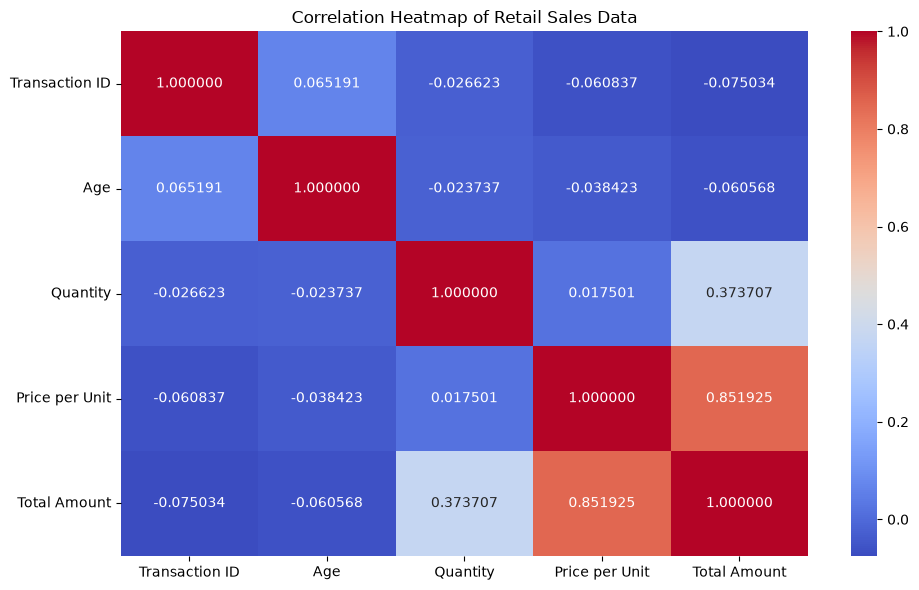

In [128]:
numerical_data=df.select_dtypes(include="number")
correlation_matrix=numerical_data.corr()
#plot heatmap
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt="2f")
plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

Price per unit and Total Amount: A strong positive correlation of 0.85 indicates than an increase in the unit price  is generally associated  with an increase in the total amount.


Quantity  and Total Amount:A very weak negative correlation of 0.37 suggests that quantity has a positive relationship with the total amount.

Age and Total Amount : A very weak negative correlation of -0.06 indicates almost no linear relationship between customer age and total amount.

Transaction Id: It has very weak correlations with the other numerical variables, so it does not show meaningful linear relationship with them.


Age and Quantity: A very weak negative correlation of -0.02 indicates almost no linear relationship between this.

  Product Category  Gender  Total Amount
0           Beauty  Female         74830
1           Beauty    Male         68685
2         Clothing  Female         81275
3         Clothing    Male         74305
4      Electronics  Female         76735
5      Electronics    Male         80170


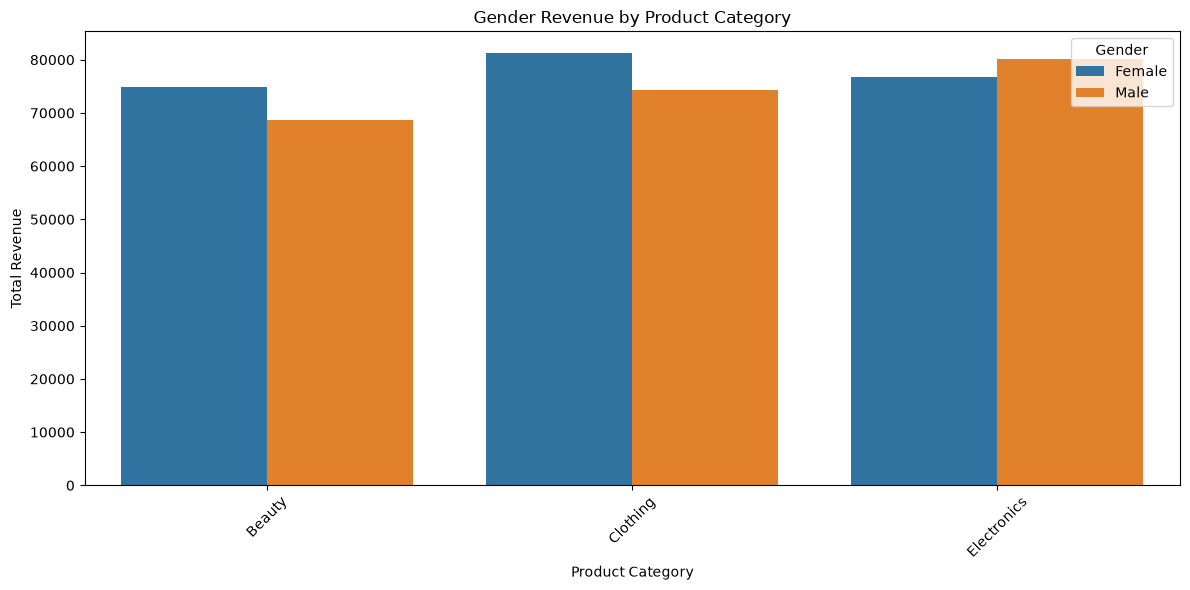

In [157]:
gender_revenue = df.groupby(['Product Category','Gender'])['Total Amount'].sum().reset_index()
print(gender_revenue)

plt.figure(figsize=(12,6))
sns.barplot(data=gender_revenue,x='Product Category',y='Total Amount',hue='Gender')
plt.title('Gender Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

Beauty: Female customer (74830) generated more revenue than  Male customer(68685)


Clothing:Female customer (81275) generated more revenue than  Male customer(74305)


Electronics: Male customer (80170) generated more revenue than Female customer (76735)



Conclusion Section:

1.Focus on High-Revenue  Product Categories: Electronics generates the highest revenue, followed clothing. The buisness should maintain sufficient inventory, offer attractive product bundles, and run targeted promotions to sustain sales in these categories.


2.Improve Beauty category sales: Beauty generates the lowest revenue among the three categories. The buisness should introduce discounts, combo offers and targeted marketing campaigns to attract more customers and increase sales.



3.Attract Younger Customers: The under 18 age group has the fewest customer records . The buisness can explore social media marketing ,student frienly offers and affordable product  to increase engagement among younger customers.